In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
import time
import joblib

from pathlib import Path

warnings.filterwarnings("ignore")


# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Hyperparameter tuning
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULTS_DIR)

Project root: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn
Data directory: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/data
Model directory: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models
Results directory: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/results


In [29]:
train_data = pd.read_csv(
    DATA_DIR / "train_data.csv"
)

test_data = pd.read_csv(
    DATA_DIR / "test_data.csv"
)

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)

display(train_data.head())

Training dataset: (5616, 20)
Testing dataset: (1405, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),70.70,140.70,Yes
1,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),84.35,1302.65,No
2,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.55,6373.10,No
3,Male,0,No,No,5,Yes,No,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),65.60,339.90,No
4,Male,0,No,No,26,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.30,511.25,No


In [30]:
TARGET_COLUMN = "Churn"

# Remove target and customer identifier
X_train = train_data.drop(
    columns=[TARGET_COLUMN, "customerID"],
    errors="ignore"
)

X_test = test_data.drop(
    columns=[TARGET_COLUMN, "customerID"],
    errors="ignore"
)

y_train = train_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

y_test = test_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

X_train: (5616, 19)
y_train: (5616,)
X_test: (1405, 19)
y_test: (1405,)

Training target distribution:
Churn
0    0.735577
1    0.264423
Name: proportion, dtype: float64


In [31]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 3
Number of categorical features: 16


In [32]:
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [33]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = "f1"

print("Cross-validation configuration:")
print("Number of folds:", cv.n_splits)
print("Scoring metric:", SCORING)

Cross-validation configuration:
Number of folds: 5
Scoring metric: f1


In [53]:
def run_grid_search(
    model_name,
    pipeline,
    param_grid
):
    print("\n" + "=" * 70)
    print(f"STARTING HYPERPARAMETER TUNING: {model_name}")
    print("=" * 70)

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=SCORING,
        cv=cv,
        refit=True,
        n_jobs=-1,
        verbose=1,
        return_train_score=True,
        error_score="raise"
    )

    start_time = time.time()

    grid_search.fit(X_train, y_train)

    end_time = time.time()

    execution_time = end_time - start_time

    print("\nTuning completed!")

    print("Best Parameters:")
    print(grid_search.best_params_)

    print(
        f"\nBest Cross-Validation F1: "
        f"{grid_search.best_score_:.4f}"
    )

    print(
        f"Execution Time: "
        f"{execution_time:.2f} seconds"
    )

    result = {
        "Model": model_name,
        "Best CV F1": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_,
        "Execution Time (seconds)": execution_time,
        "Best Estimator": grid_search.best_estimator_
    }

    return result

In [35]:
model_pipelines = {

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                random_state=RANDOM_STATE,
                max_iter=2000
            )
        )
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=RANDOM_STATE
            )
        )
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            KNeighborsClassifier(
                n_jobs=1
            )
        )
    ]),

    "Naive Bayes": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            GaussianNB()
        )
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        (
            "classifier",
            SVC(
                probability=True,
                random_state=RANDOM_STATE
            )
        )
    ])
}

print("All five model pipelines initialized successfully!")

for model_name in model_pipelines:
    print("-", model_name)

All five model pipelines initialized successfully!
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- SVM


In [36]:
lr_param_grid = [

    {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__penalty": ["l1", "l2"],
        "classifier__solver": ["liblinear"],
        "classifier__class_weight": [None, "balanced"]
    },

    {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__penalty": ["l2"],
        "classifier__solver": ["lbfgs"],
        "classifier__class_weight": [None, "balanced"]
    }
]

print("Logistic Regression parameter grid defined!")

Logistic Regression parameter grid defined!


In [37]:
dt_param_grid = {
    "classifier__criterion": [
        "gini",
        "entropy"
    ],

    "classifier__max_depth": [
        None,
        5,
        10,
        15
    ],

    "classifier__min_samples_split": [
        2,
        10
    ],

    "classifier__min_samples_leaf": [
        1,
        5
    ],

    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

print("Decision Tree parameter grid defined!")

Decision Tree parameter grid defined!


In [38]:
knn_param_grid = {
    "classifier__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],

    "classifier__weights": [
        "uniform",
        "distance"
    ],

    "classifier__p": [
        1,
        2
    ]
}

print("KNN parameter grid defined!")

KNN parameter grid defined!


In [39]:
nb_param_grid = {
    "classifier__var_smoothing": np.logspace(
        -12,
        -6,
        7
    )
}

print("Naive Bayes parameter grid defined!")
print(nb_param_grid)

Naive Bayes parameter grid defined!
{'classifier__var_smoothing': array([1.e-12, 1.e-11, 1.e-10, 1.e-09, 1.e-08, 1.e-07, 1.e-06])}


In [40]:
svm_param_grid = {
    "classifier__C": [
        0.1,
        1,
        10
    ],

    "classifier__gamma": [
        "scale",
        0.01,
        0.1,
        1
    ],

    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

print("SVM parameter grid defined!")

SVM parameter grid defined!


In [41]:
param_grids = {
    "Logistic Regression": lr_param_grid,
    "Decision Tree": dt_param_grid,
    "KNN": knn_param_grid,
    "Naive Bayes": nb_param_grid,
    "SVM": svm_param_grid
}

tuning_results = {}

for model_name, pipeline in model_pipelines.items():

    result = run_grid_search(
        model_name=model_name,
        pipeline=pipeline,
        param_grid=param_grids[model_name]
    )

    tuning_results[model_name] = result

print("\nAll five hyperparameter tuning experiments completed!")


STARTING HYPERPARAMETER TUNING: Logistic Regression
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Tuning completed!
Best Parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}

Best Cross-Validation F1: 0.6304
Execution Time: 2.78 seconds

STARTING HYPERPARAMETER TUNING: Decision Tree
Fitting 5 folds for each of 64 candidates, totalling 320 fits

Tuning completed!
Best Parameters:
{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Best Cross-Validation F1: 0.6218
Execution Time: 3.82 seconds

STARTING HYPERPARAMETER TUNING: KNN
Fitting 5 folds for each of 28 candidates, totalling 140 fits

Tuning completed!
Best Parameters:
{'classifier__n_neighbors': 21, 'classifier__p': 1, 'classifier__weights': 'uniform'}

Best Cross-Validation F1: 0.5962
Execution Time: 5.43 s

In [42]:
tuning_summary = []

for model_name, result in tuning_results.items():

    tuning_summary.append({
        "Model": model_name,
        "Best CV F1": result["Best CV F1"],
        "Best Parameters": str(result["Best Parameters"]),
        "Execution Time (seconds)": result["Execution Time (seconds)"]
    })

tuning_summary_df = pd.DataFrame(tuning_summary)

display(
    tuning_summary_df.style.format({
        "Best CV F1": "{:.4f}",
        "Execution Time (seconds)": "{:.2f}"
    })
)

,Model,Best CV F1,Best Parameters,Execution Time (seconds)
0,Logistic Regression,0.6304,"{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}",2.78
1,Decision Tree,0.6218,"{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}",3.82
2,KNN,0.5962,"{'classifier__n_neighbors': 21, 'classifier__p': 1, 'classifier__weights': 'uniform'}",5.43
3,Naive Bayes,0.5947,{'classifier__var_smoothing': np.float64(1e-12)},0.43
4,SVM,0.6240,"{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale'}",61.97


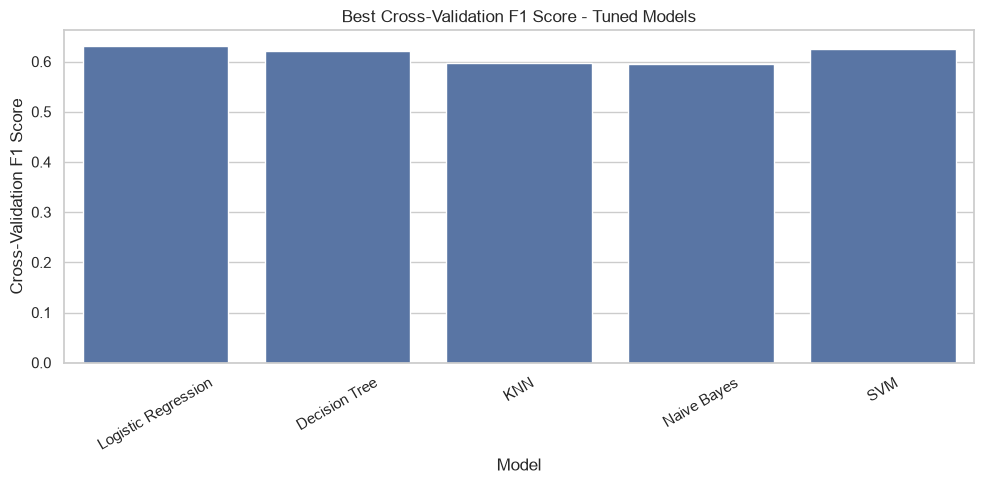

In [43]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_summary_df,
    x="Model",
    y="Best CV F1"
)

plt.title("Best Cross-Validation F1 Score - Tuned Models")
plt.xlabel("Model")
plt.ylabel("Cross-Validation F1 Score")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [44]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, predictions)
    }

In [45]:
tuned_models = {}
tuned_test_results = []

for model_name, result in tuning_results.items():

    best_model = result["Best Estimator"]

    tuned_models[model_name] = best_model

    metrics = evaluate_model(
        best_model,
        X_test,
        y_test
    )

    tuned_test_results.append({
        "Model": model_name,
        **metrics
    })

tuned_results_df = pd.DataFrame(
    tuned_test_results
)

display(
    tuned_results_df.style.format({
        col: "{:.4f}"
        for col in [
            "Accuracy", "AUC", "Precision",
            "Recall", "F1", "MCC"
        ]
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7409,0.8397,0.5070,0.7796,0.6144,0.4549
1,Decision Tree,0.7338,0.8266,0.4983,0.7715,0.6055,0.4411
2,KNN,0.7815,0.8239,0.5953,0.5457,0.5694,0.4241
3,Naive Bayes,0.6847,0.8067,0.4488,0.8360,0.5840,0.4114
4,SVM,0.7594,0.8245,0.5315,0.7715,0.6294,0.4776


In [46]:
tuned_results_df.to_csv(
    RESULTS_DIR / "tuned_model_comparison.csv",
    index=False
)

tuning_summary_df.to_csv(
    RESULTS_DIR / "hyperparameter_tuning_summary.csv",
    index=False
)

print("Tuned model results exported successfully!")

Tuned model results exported successfully!


In [47]:
baseline_results_df = pd.read_csv(
    RESULTS_DIR / "baseline_comparison.csv"
)

baseline_results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.802847,0.840267,0.661017,0.524194,0.584708,0.462990
1,Decision Tree,0.714591,0.649778,0.464198,0.505376,0.483912,0.287654
2,KNN,0.759431,0.771967,0.551205,0.491935,0.519886,0.361120
3,Naive Bayes,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444
4,SVM,0.797865,0.783256,0.661765,0.483871,0.559006,0.440870


In [60]:
comparison_metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

baseline_vs_tuned = baseline_results_df.merge(
    tuned_results_df,
    on="Model",
    suffixes=("_Baseline", "_Tuned"),
)

display(baseline_vs_tuned)

,Model,Accuracy_Baseline,AUC_Baseline,Precision_Baseline,Recall_Baseline,F1_Baseline,MCC_Baseline,Accuracy_Tuned,AUC_Tuned,Precision_Tuned,Recall_Tuned,F1_Tuned,MCC_Tuned
0,Logistic Regression,0.802847,0.840267,0.661017,0.524194,0.584708,0.462990,0.740925,0.839749,0.506993,0.779570,0.614407,0.454934
1,Decision Tree,0.714591,0.649778,0.464198,0.505376,0.483912,0.287654,0.733808,0.826554,0.498264,0.771505,0.605485,0.441130
2,KNN,0.759431,0.771967,0.551205,0.491935,0.519886,0.361120,0.781495,0.823874,0.595308,0.545699,0.569425,0.424115
3,Naive Bayes,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444
4,SVM,0.797865,0.783256,0.661765,0.483871,0.559006,0.440870,0.759431,0.824548,0.531481,0.771505,0.629386,0.477625


In [49]:
for metric in comparison_metrics:

    baseline_vs_tuned[f"{metric}_Change"] = (
        baseline_vs_tuned[f"{metric}_Tuned"]
        -
        baseline_vs_tuned[f"{metric}_Baseline"]
    )

display(
    baseline_vs_tuned.style.format({
        col: "{:+.4f}"
        for col in baseline_vs_tuned.columns
        if col.endswith("_Change")
    })
)

,Model,Accuracy_Baseline,AUC_Baseline,Precision_Baseline,Recall_Baseline,F1_Baseline,MCC_Baseline,Accuracy_Tuned,AUC_Tuned,Precision_Tuned,Recall_Tuned,F1_Tuned,MCC_Tuned,Accuracy_Change,AUC_Change,Precision_Change,Recall_Change,F1_Change,MCC_Change
0,Logistic Regression,0.802847,0.840267,0.661017,0.524194,0.584708,0.462990,0.740925,0.839749,0.506993,0.779570,0.614407,0.454934,-0.0619,-0.0005,-0.1540,+0.2554,+0.0297,-0.0081
1,Decision Tree,0.714591,0.649778,0.464198,0.505376,0.483912,0.287654,0.733808,0.826554,0.498264,0.771505,0.605485,0.441130,+0.0192,+0.1768,+0.0341,+0.2661,+0.1216,+0.1535
2,KNN,0.759431,0.771967,0.551205,0.491935,0.519886,0.361120,0.781495,0.823874,0.595308,0.545699,0.569425,0.424115,+0.0221,+0.0519,+0.0441,+0.0538,+0.0495,+0.0630
3,Naive Bayes,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
4,SVM,0.797865,0.783256,0.661765,0.483871,0.559006,0.440870,0.759431,0.824548,0.531481,0.771505,0.629386,0.477625,-0.0384,+0.0413,-0.1303,+0.2876,+0.0704,+0.0368


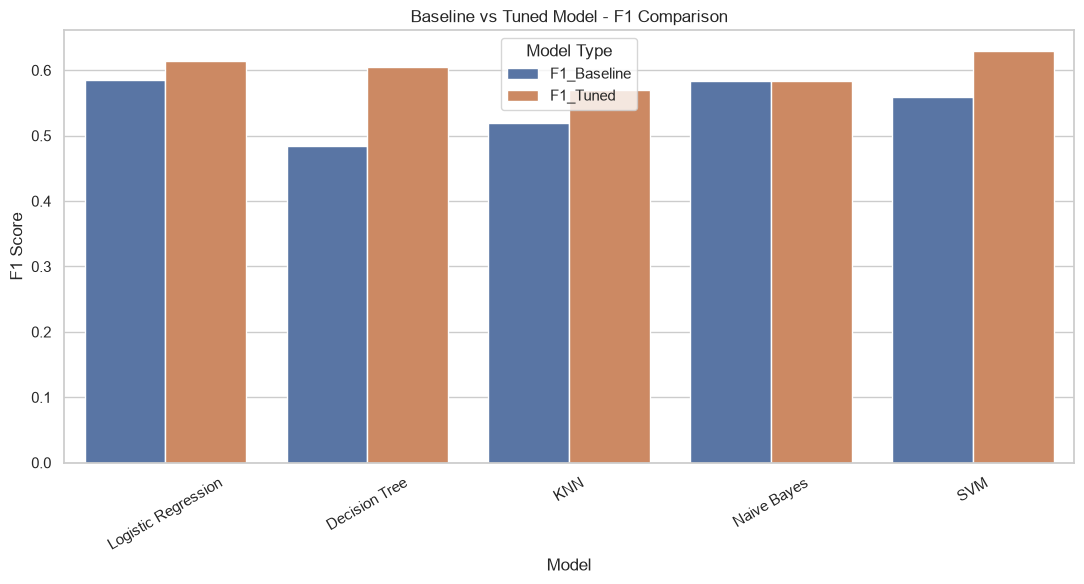

In [50]:
f1_comparison = baseline_vs_tuned[
    [
        "Model",
        "F1_Baseline",
        "F1_Tuned"
    ]
].melt(
    id_vars="Model",
    var_name="Model Type",
    value_name="F1 Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=f1_comparison,
    x="Model",
    y="F1 Score",
    hue="Model Type"
)

plt.title("Baseline vs Tuned Model - F1 Comparison")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [51]:
for model_name, model in tuned_models.items():

    filename = (
        model_name.lower()
        .replace(" ", "_")
        + "_tuned.joblib"
    )

    model_path = MODEL_DIR / filename

    joblib.dump(
        model,
        model_path
    )

    print(f"{model_name} saved at: {model_path}")

Logistic Regression saved at: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/logistic_regression_tuned.joblib
Decision Tree saved at: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/decision_tree_tuned.joblib
KNN saved at: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/knn_tuned.joblib
Naive Bayes saved at: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/naive_bayes_tuned.joblib
SVM saved at: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/svm_tuned.joblib


In [52]:
print("=" * 70)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 70)

print("\nSaved tuned models:")

for path in MODEL_DIR.glob("*_tuned.joblib"):
    print("-", path.name)

print("\nExported result files:")

for path in RESULTS_DIR.glob("*.csv"):
    print("-", path.name)

HYPERPARAMETER TUNING COMPLETED

Saved tuned models:
- svm_tuned.joblib
- naive_bayes_tuned.joblib
- logistic_regression_tuned.joblib
- knn_tuned.joblib
- decision_tree_tuned.joblib

Exported result files:
- svm_metrics.csv
- tuned_model_comparison.csv
- decision_tree_metrics.csv
- knn_metrics.csv
- naive_bayes_metrics.csv
- logistic_regression_metrics.csv
- hyperparameter_tuning_summary.csv
- baseline_comparison.csv


In [61]:
for model_name, model in tuned_models.items():

    print("\n" + "=" * 70)
    print(f"{model_name} - CLASSIFICATION REPORT")
    print("=" * 70)

    predictions = model.predict(X_test)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["No Churn", "Churn"],
            digits=4,
            zero_division=0
        )
    )


Logistic Regression - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn     0.9016    0.7270    0.8049      1033
       Churn     0.5070    0.7796    0.6144       372

    accuracy                         0.7409      1405
   macro avg     0.7043    0.7533    0.7097      1405
weighted avg     0.7971    0.7409    0.7545      1405


Decision Tree - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn     0.8975    0.7202    0.7991      1033
       Churn     0.4983    0.7715    0.6055       372

    accuracy                         0.7338      1405
   macro avg     0.6979    0.7459    0.7023      1405
weighted avg     0.7918    0.7338    0.7479      1405


KNN - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn     0.8412    0.8664    0.8536      1033
       Churn     0.5953    0.5457    0.5694       372

    accuracy                         0.7815      1405
   macro avg   

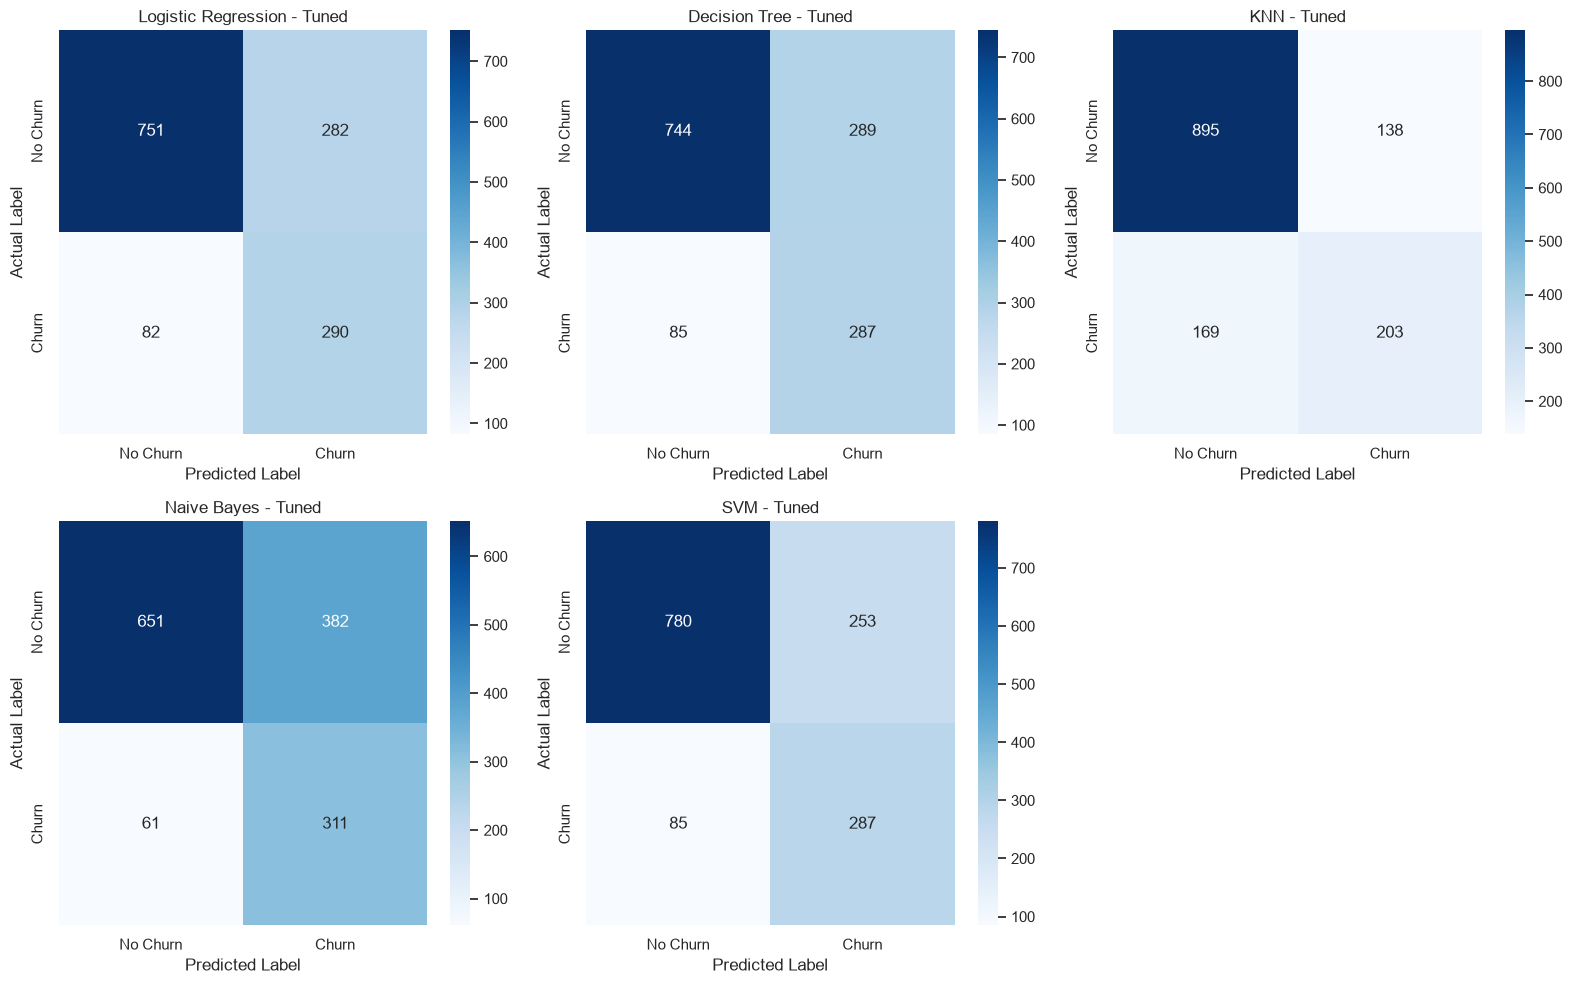

In [62]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

for ax, (model_name, model) in zip(
    axes.flatten(),
    tuned_models.items()
):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(f"{model_name} - Tuned")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

axes.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [63]:
baseline_vs_tuned.to_csv(
    RESULTS_DIR / "baseline_vs_tuned_comparison.csv",
    index=False
)

print("Final comparison exported successfully!")

Final comparison exported successfully!


## Classification Threshold Optimization

By default, binary classification models use a threshold of 0.5 to convert predicted probabilities into class labels.

If the predicted probability of churn is greater than or equal to 0.5, the customer is classified as a churner. Otherwise, the customer is classified as a non-churner.

However, the default threshold may not provide the best balance between Precision and Recall, particularly when working with imbalanced datasets.

Threshold optimization involves evaluating different probability thresholds and selecting the threshold that provides the best classification performance according to a chosen evaluation metric.

In this experiment, we will investigate different classification thresholds for Logistic Regression and Support Vector Machine.

We will use F1 Score as the primary optimization metric and additionally examine Precision and Recall.

Threshold selection will be performed using a separate validation subset created from the training dataset. The original test dataset will remain untouched for final evaluation.

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Subtraining data:", X_subtrain.shape)
print("Validation data:", X_validation.shape)

Subtraining data: (4492, 19)
Validation data: (1124, 19)


In [65]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Subtraining data:", X_subtrain.shape)
print("Validation data:", X_validation.shape)

Subtraining data: (4492, 19)
Validation data: (1124, 19)


In [66]:
threshold_models = {
    "Logistic Regression": tuning_results[
        "Logistic Regression"
    ]["Best Estimator"],

    "SVM": tuning_results[
        "SVM"
    ]["Best Estimator"]
}

print("Models selected for threshold optimization:")
print(list(threshold_models.keys()))

Models selected for threshold optimization:
['Logistic Regression', 'SVM']


In [67]:
thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = []

for model_name, best_model in threshold_models.items():

    # Create an unfitted copy with the best parameters
    validation_model = clone(best_model)

    # Train only on the subtraining dataset
    validation_model.fit(
        X_subtrain,
        y_subtrain
    )

    # Obtain churn probabilities
    probabilities = validation_model.predict_proba(
        X_validation
    )[:, 1]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(
                y_validation, predictions
            ),
            "Precision": precision_score(
                y_validation, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_validation, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_validation, predictions, zero_division=0
            ),
            "MCC": matthews_corrcoef(
                y_validation, predictions
            )
        })

threshold_results_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_results_df.style.format({
        col: "{:.4f}"
        for col in [
            "Threshold", "Accuracy",
            "Precision", "Recall", "F1", "MCC"
        ]
    })
)

,Model,Threshold,Accuracy,Precision,Recall,F1,MCC
0,Logistic Regression,0.2000,0.6023,0.3964,0.9663,0.5622,0.4033
1,Logistic Regression,0.2500,0.6272,0.4111,0.9495,0.5738,0.4168
2,Logistic Regression,0.3000,0.6548,0.4295,0.9327,0.5881,0.4348
3,Logistic Regression,0.3500,0.6824,0.4502,0.9125,0.6029,0.4528
4,Logistic Regression,0.4000,0.7082,0.4718,0.8721,0.6123,0.4599
5,Logistic Regression,0.4500,0.7313,0.4951,0.8552,0.6272,0.4798
6,Logistic Regression,0.5000,0.7527,0.5204,0.8148,0.6352,0.4881
7,Logistic Regression,0.5500,0.7660,0.5409,0.7576,0.6311,0.4809
8,Logistic Regression,0.6000,0.7740,0.5576,0.7003,0.6209,0.4690
9,Logistic Regression,0.6500,0.7874,0.5879,0.6532,0.6188,0.4732


In [68]:
optimal_thresholds = {}

for model_name in threshold_models:

    model_results = threshold_results_df[
        threshold_results_df["Model"] == model_name
    ]

    best_row = model_results.loc[
        model_results["F1"].idxmax()
    ]

    optimal_thresholds[model_name] = (
        best_row["Threshold"]
    )

    print("\nModel:", model_name)
    print("Optimal threshold:", best_row["Threshold"])
    print("Validation F1:", round(best_row["F1"], 4))
    print("Validation Precision:", round(best_row["Precision"], 4))
    print("Validation Recall:", round(best_row["Recall"], 4))


Model: Logistic Regression
Optimal threshold: 0.49999999999999994
Validation F1: 0.6352
Validation Precision: 0.5204
Validation Recall: 0.8148

Model: SVM
Optimal threshold: 0.39999999999999997
Validation F1: 0.6333
Validation Precision: 0.5758
Validation Recall: 0.7037


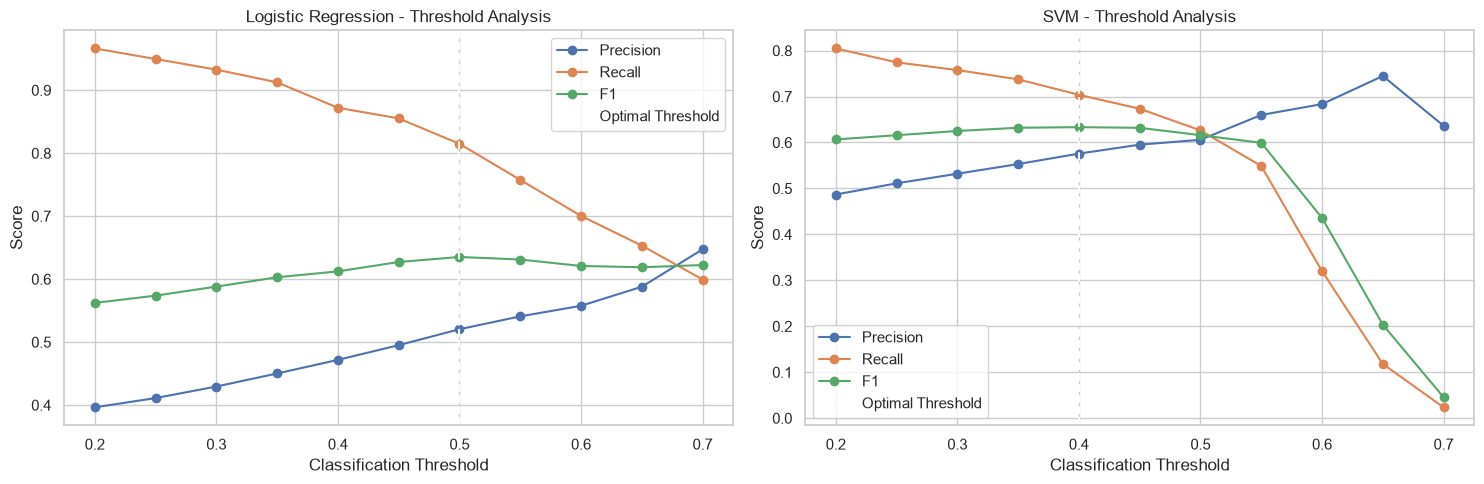

In [69]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

for ax, model_name in zip(
    axes,
    threshold_models.keys()
):

    model_results = threshold_results_df[
        threshold_results_df["Model"] == model_name
    ]

    for metric in ["Precision", "Recall", "F1"]:

        ax.plot(
            model_results["Threshold"],
            model_results[metric],
            marker="o",
            label=metric
        )

    ax.axvline(
        optimal_thresholds[model_name],
        linestyle="--",
        label="Optimal Threshold"
    )

    ax.set_title(f"{model_name} - Threshold Analysis")
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel("Score")
    ax.legend()

plt.tight_layout()
plt.show()

In [70]:
final_models = {}

for model_name, best_model in threshold_models.items():

    final_model = clone(best_model)

    final_model.fit(
        X_train,
        y_train
    )

    final_models[model_name] = final_model

print("Final models trained on complete training data!")

Final models trained on complete training data!


In [71]:
threshold_test_results = []

for model_name, model in final_models.items():

    threshold = optimal_thresholds[model_name]

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    metrics = {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, predictions)
    }

    threshold_test_results.append(metrics)

threshold_test_df = pd.DataFrame(
    threshold_test_results
)

display(
    threshold_test_df.style.format({
        col: "{:.4f}"
        for col in [
            "Threshold", "Accuracy", "AUC",
            "Precision", "Recall", "F1", "MCC"
        ]
    })
)

,Model,Threshold,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.5000,0.7409,0.8397,0.5070,0.7796,0.6144,0.4549
1,SVM,0.4000,0.7822,0.8245,0.5753,0.6774,0.6222,0.4737


In [72]:
comparison = tuned_results_df[
    tuned_results_df["Model"].isin(
        ["Logistic Regression", "SVM"]
    )
].merge(
    threshold_test_df,
    on="Model",
    suffixes=("_Tuned", "_Threshold")
)

display(comparison)

,Model,Accuracy_Tuned,AUC_Tuned,Precision_Tuned,Recall_Tuned,F1_Tuned,MCC_Tuned,Threshold,Accuracy_Threshold,AUC_Threshold,Precision_Threshold,Recall_Threshold,F1_Threshold,MCC_Threshold
0,Logistic Regression,0.740925,0.839749,0.506993,0.779570,0.614407,0.454934,0.5,0.740925,0.839749,0.506993,0.779570,0.614407,0.454934
1,SVM,0.759431,0.824548,0.531481,0.771505,0.629386,0.477625,0.4,0.782206,0.824548,0.575342,0.677419,0.622222,0.473744


In [73]:
for model_name, model in final_models.items():

    filename = (
        model_name.lower().replace(" ", "_")
        + "_threshold_optimized.joblib"
    )

    joblib.dump(
        {
            "model": model,
            "threshold": optimal_thresholds[model_name]
        },
        MODEL_DIR / filename
    )

threshold_test_df.to_csv(
    RESULTS_DIR / "threshold_optimized_results.csv",
    index=False
)

print("Threshold-optimized models saved!")

Threshold-optimized models saved!


In [74]:
svm_original = tuned_models["SVM"]
svm_final = final_models["SVM"]

original_probabilities = svm_original.predict_proba(X_test)[:, 1]
final_probabilities = svm_final.predict_proba(X_test)[:, 1]

print(
    "Maximum probability difference:",
    np.max(
        np.abs(
            original_probabilities - final_probabilities
        )
    )
)

for threshold in [0.4, 0.5]:

    predictions = (
        final_probabilities >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["No Churn", "Churn"],
            digits=4
        )
    )

Maximum probability difference: 0.0

Threshold: 0.4
              precision    recall  f1-score   support

    No Churn     0.8759    0.8199    0.8470      1033
       Churn     0.5753    0.6774    0.6222       372

    accuracy                         0.7822      1405
   macro avg     0.7256    0.7487    0.7346      1405
weighted avg     0.7963    0.7822    0.7875      1405


Threshold: 0.5
              precision    recall  f1-score   support

    No Churn     0.8563    0.8596    0.8580      1033
       Churn     0.6060    0.5995    0.6027       372

    accuracy                         0.7907      1405
   macro avg     0.7311    0.7295    0.7303      1405
weighted avg     0.7900    0.7907    0.7904      1405



In [75]:
probability_threshold_results = []

for model_name, model in final_models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    thresholds_to_evaluate = (
        [0.5, optimal_thresholds[model_name]]
        if model_name == "SVM"
        else [optimal_thresholds[model_name]]
    )

    for threshold in set(thresholds_to_evaluate):

        predictions = (
            probabilities >= threshold
        ).astype(int)

        probability_threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, predictions),
            "AUC": roc_auc_score(y_test, probabilities),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "MCC": matthews_corrcoef(y_test, predictions)
        })

probability_comparison_df = pd.DataFrame(
    probability_threshold_results
)

display(
    probability_comparison_df.style.format({
        col: "{:.4f}"
        for col in [
            "Threshold", "Accuracy", "AUC",
            "Precision", "Recall", "F1", "MCC"
        ]
    })
)

,Model,Threshold,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.5000,0.7409,0.8397,0.5070,0.7796,0.6144,0.4549
1,SVM,0.5000,0.7907,0.8245,0.6060,0.5995,0.6027,0.4607
2,SVM,0.4000,0.7822,0.8245,0.5753,0.6774,0.6222,0.4737


In [76]:
final_model = clone(
    tuned_models["SVM"]
)

final_model.fit(
    X_train,
    y_train
)

final_threshold = 0.40

final_artifact = {
    "model": final_model,
    "threshold": final_threshold,
    "model_name": "SVM",
    "kernel": "rbf",
    "metrics": {
        "accuracy": 0.7822,
        "auc": 0.8245,
        "precision": 0.5753,
        "recall": 0.6774,
        "f1": 0.6222,
        "mcc": 0.4737
    }
}

joblib.dump(
    final_artifact,
    MODEL_DIR / "final_churn_model.joblib"
)

print("Final model saved successfully!")

Final model saved successfully!
